# Where the next dollar per order comes from
### Pricing, demand and customer analysis for a quick-service coffee chain

A revenue growth team keeps asking one question: **which lever moves revenue per order (price, basket, channel or loyalty), and how sure are we?** This notebook answers it with 100,000 orders. Thirty years of Starbucks 10-K filings add strategic context.

**Data.** Every number is read from the warehouse tables built by this repo's pipeline (`qsr_marts.*`):
- 100,000 orders from 500 stores and 14,988 customers, Jan 2024 – Dec 2025
- Store counts and keyword trends parsed from Starbucks' annual reports, FY1996–FY2025

By default the notebook runs on the local DuckDB file. Set `WAREHOUSE=bigquery` and `GCP_PROJECT=<id>` to read the same tables from BigQuery.

| # | Finding | Evidence |
|---|---|---|
| 1 | **Channel is the biggest lever.** App orders average **$18.08** vs **$12.49** in every other channel (+45%). | App: 42.5% of orders, 51.7% of revenue |
| 2 | **62% of the app gap is basket composition** (+0.80 items, +1.19 customizations, more food). The other $2.09 is a same-basket app premium. | Regression decomposition, R² 0.967 out of sample |
| 3 | **The rewards "uplift" comes from channel mix.** Member orders are $1.63 (11.6%) larger overall but within ±$0.11 inside every channel. | Adjusted effect +$0.02, 95% CI −$0.04 to +$0.09 |
| 4 | **Age gates app adoption, not spend.** App share: 55% under 35, ~35% at 35–54, 10% at 55+. Age has no effect on ticket once channel is controlled. | Age gap $2.50 raw, $0.02 after channel (p = 0.78) |
| 5 | **Customizations are a pricing surface.** Each one is worth ~$0.93; together they are 11% of revenue, on 81% of orders. | Ticket model coefficients |
| 6 | **Price elasticity can't be estimated here** (no price variation), so I sized a test: **~4,000 orders per arm** detects a 2% ticket change. | Power analysis with covariate adjustment |
| 7 | **Demand follows the clock, not the calendar.** Orders peak at 7am, noon and 4pm, and 39% arrive before 11am. Weekday and season effects are not significant. | χ² p = 0.63 (weekday), 0.73 (month) |
| 8 | **Satisfaction tracks the channel, not the wait.** Drive-thru scores 0.42 points below the app. Wait time looks harmful only when pooled. | −0.037/min pooled vs +0.001/min within channel |

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "pipeline").is_dir())
sys.path[:0] = [str(ROOT), str(ROOT / "analysis")]
from pipeline.config import load_settings
from pipeline.warehouse import open_warehouse
import style as S

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
S.apply()
%matplotlib inline

settings = load_settings()                      # WAREHOUSE=bigquery reads the same tables from BigQuery
wh = open_warehouse(settings)
q = wh.query
T = wh.fq

orders = q(f"select * from {T('qsr_marts', 'fct_orders')}")
for c in ["is_app_order", "is_rewards_member", "has_food_item", "is_order_ahead"]:
    orders[c] = orders[c].astype(bool)
orders["order_date"] = pd.to_datetime(orders["order_date"])
print(f"warehouse={settings.warehouse}  orders={len(orders):,}  customers={orders.customer_id.nunique():,}  "
      f"stores={orders.store_id.nunique()}  dates={orders.order_date.min():%Y-%m-%d}..{orders.order_date.max():%Y-%m-%d}  "
      f"revenue=${orders.revenue.sum():,.0f}")

warehouse=duckdb  orders=100,000  customers=14,988  stores=500  dates=2024-01-01..2025-12-30  revenue=$1,486,677


## 0. What this data can (and can't) support

Before building segments or models, I tested whether the structure they need exists.

- **Customer persistence.** If customer IDs carried real habits, customers' app share and average ticket would vary more across customers than with shuffled IDs. They vary more than a random shuffle, but **exactly as much as a shuffle within age group**. Beyond age, a customer's history says nothing about their next order.
- **Frequency.** Orders per customer have variance ≈ mean (6.56 vs 6.67). That is the signature of Poisson noise, so there are no heavy and light users to segment.
- **Per-order attributes.** For 93–100% of customers, rewards status, channel, region and store change from one order to the next.
- **Prices.** There are no menu prices and no price changes, so price elasticity cannot be identified.

So the analysis segments by **age**, analyzes rewards and channel at the **order** level, and skips RFM/CLV, which would only sort noise. Price response is treated as something to **test**. Results are identical across regions, store types and drink categories, which suggests the order data is simulated. The methods are the deliverable and the numbers illustrate them. The 10-K data in section 5 is real.

In [2]:
rng = np.random.default_rng(7)
x = orders[["customer_id", "age_group", "is_app_order", "revenue"]].assign(app=lambda d: d.is_app_order.astype(float))

def between_customer_var(d):
    g = d.groupby("customer_id").agg(app=("app", "mean"), ticket=("revenue", "mean"))
    return g.app.var(), g.ticket.var()

obs = between_customer_var(x)
shuffled_all = np.array([between_customer_var(x.assign(customer_id=rng.permutation(x.customer_id.values))) for _ in range(25)])
shuffled_age = np.array([between_customer_var(x.assign(customer_id=x.groupby("age_group").customer_id.transform(
    lambda s: rng.permutation(s.values)))) for _ in range(25)])

persistence = pd.DataFrame({
    "observed": obs,
    "IDs shuffled at random": shuffled_all.mean(0),
    "IDs shuffled within age group": shuffled_age.mean(0),
}, index=["variance of customers' app-order share", "variance of customers' average ticket"])
display(persistence)

per_cust = orders.groupby("customer_id").size()
print(f"orders per customer: mean {per_cust.mean():.2f}, variance {per_cust.var():.2f}  (Poisson => variance = mean)")
print("attributes that vary across a customer's orders (share of customers with 2+ orders):")
multi = orders.groupby("customer_id").filter(lambda g: len(g) > 1).groupby("customer_id")
print((multi[["age_group", "gender", "is_rewards_member", "order_channel", "region", "store_id"]].nunique() > 1).mean().round(3).to_string())

,observed,IDs shuffled at random,IDs shuffled within age group
variance of customers' app-order share,0.062,0.045,0.062
variance of customers' average ticket,6.103,5.541,6.066


orders per customer: mean 6.67, variance 6.56  (Poisson => variance = mean)
attributes that vary across a customer's orders (share of customers with 2+ orders):


age_group           0.000
gender              0.000
is_rewards_member   0.934
order_channel       0.965
region              0.991
store_id            1.000


## 1. Revenue structure by channel

In [3]:
kpis = q(f"select * from {T('qsr_marts', 'mart_channel_kpis')}").set_index("order_channel").loc[S.CHANNEL_ORDER]
display(kpis[["orders", "order_share", "revenue_share", "avg_ticket", "items_per_order", "customizations_per_order",
              "food_attach_rate", "rewards_order_share", "avg_fulfillment_min", "avg_satisfaction"]])
app, other = orders[orders.is_app_order], orders[~orders.is_app_order]
print(f"App ticket ${app.revenue.mean():.2f} vs other channels ${other.revenue.mean():.2f} "
      f"(+{app.revenue.mean() / other.revenue.mean() - 1:.0%}); app = {len(app) / len(orders):.1%} of orders, "
      f"{app.revenue.sum() / orders.revenue.sum():.1%} of revenue")

,orders,order_share,revenue_share,avg_ticket,items_per_order,customizations_per_order,food_attach_rate,rewards_order_share,avg_fulfillment_min,avg_satisfaction
order_channel,,,,,,,,,,
Mobile App,42521,0.425,0.517,18.080,4.200,2.500,0.400,0.646,4.510,3.857
Drive-Thru,27996,0.280,0.235,12.480,3.400,1.300,0.254,0.352,5.800,3.443
In-Store Cashier,22063,0.221,0.186,12.510,3.410,1.310,0.250,0.354,3.200,3.700
Kiosk,7420,0.074,0.062,12.490,3.400,1.300,0.258,0.345,4.010,3.598


App ticket $18.08 vs other channels $12.49 (+45%); app = 42.5% of orders, 51.7% of revenue


PosixPath('/home/claude/qsr-revenue-growth/analysis/figures/fig1_channel_economics.png')

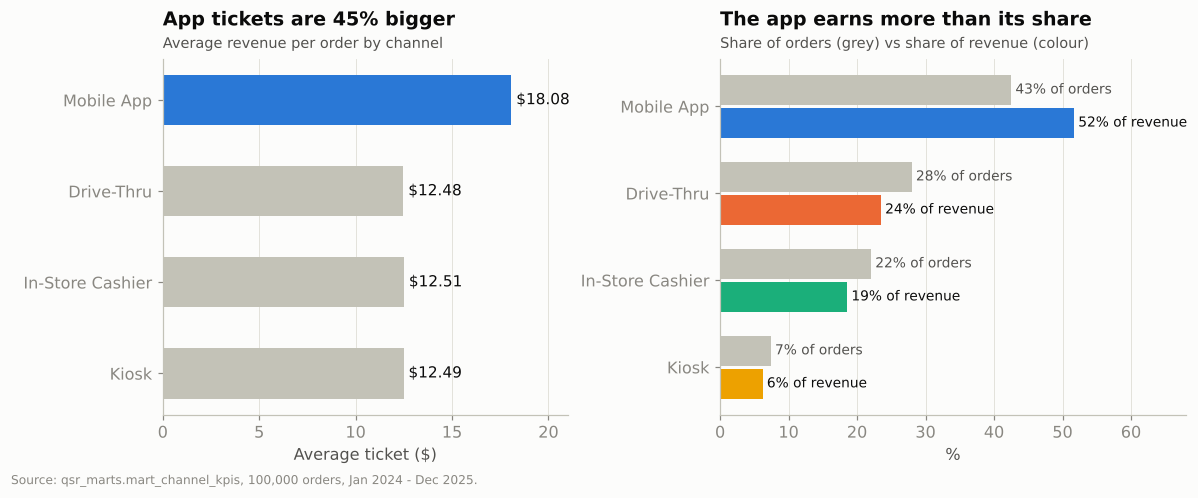

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.15], "wspace": 0.35})
ax = axes[0]
chs = S.CHANNEL_ORDER[::-1]
vals = kpis.loc[chs, "avg_ticket"]
ax.barh(chs, vals, color=[S.CHANNEL_COLORS[c] if c == "Mobile App" else S.NEUTRAL for c in chs], height=0.55)
for i, v in enumerate(vals):
    ax.text(v + 0.25, i, f"${v:.2f}", va="center", color=S.INK, fontsize=10)
ax.set_xlim(0, 21); ax.grid(axis="y", visible=False); ax.set_xlabel("Average ticket ($)")
ax.set_title("App tickets are 45% bigger")
S.subtitle(ax, "Average revenue per order by channel")

ax = axes[1]
y = np.arange(len(chs))
ax.barh(y + 0.19, kpis.loc[chs, "order_share"] * 100, height=0.34, color=S.NEUTRAL, label="Share of orders")
ax.barh(y - 0.19, kpis.loc[chs, "revenue_share"] * 100, height=0.34,
        color=[S.CHANNEL_COLORS[c] for c in chs], label="Share of revenue")
for i, c in enumerate(chs):
    ax.text(kpis.loc[c, "order_share"] * 100 + 0.6, i + 0.19, f"{kpis.loc[c, 'order_share']:.0%} of orders", va="center", fontsize=9, color=S.INK_2)
    ax.text(kpis.loc[c, "revenue_share"] * 100 + 0.6, i - 0.19, f"{kpis.loc[c, 'revenue_share']:.0%} of revenue", va="center", fontsize=9, color=S.INK)
ax.set_yticks(y, chs); ax.set_xlim(0, 68); ax.grid(axis="y", visible=False); ax.set_xlabel("%")
ax.set_title("The app earns more than its share")
S.subtitle(ax, "Share of orders (grey) vs share of revenue (colour)")
S.source(fig, "Source: qsr_marts.mart_channel_kpis, 100,000 orders, Jan 2024 - Dec 2025.")
S.save(fig, "fig1_channel_economics")

The app is the only channel that behaves differently: Drive-Thru, In-Store and Kiosk tickets are within 3 cents of each other. The rest of the notebook asks **why** the app is different and how much of that can be moved.

## 2. Pricing: what drives the ticket

The ticket model is an OLS regression of order revenue on basket composition, channel and controls (age, drink category, region, store type, rewards, order-ahead). It uses heteroskedasticity-robust (HC3) standard errors and is checked with 5-fold cross-validation.

In [5]:
d = orders.assign(food=orders.has_food_item.astype(int), app=orders.is_app_order.astype(int),
                  rewards=orders.is_rewards_member.astype(int), ahead=orders.is_order_ahead.astype(int))
CH = "C(order_channel, Treatment('Drive-Thru'))"
ticket = smf.ols(f"revenue ~ items + customizations + food + {CH} + rewards + ahead + C(age_group) + C(drink_category)"
                 " + C(region) + C(store_location_type)", data=d).fit(cov_type="HC3")
keep = {"Intercept": "Base charge per order", "items": "Each additional item", "customizations": "Each customization",
        "food": "Food in the order", f"{CH}[T.Mobile App]": "Mobile App (vs Drive-Thru)",
        f"{CH}[T.In-Store Cashier]": "In-Store (vs Drive-Thru)", f"{CH}[T.Kiosk]": "Kiosk (vs Drive-Thru)",
        "rewards": "Rewards member", "ahead": "Ordered ahead"}
ci = ticket.conf_int()
coef_table = pd.DataFrame({"effect_$": ticket.params[list(keep)], "ci_low": ci.loc[list(keep), 0],
                           "ci_high": ci.loc[list(keep), 1], "p_value": ticket.pvalues[list(keep)]}).rename(index=keep)
display(coef_table.round(3))
others = [k for k in ticket.params.index if k.startswith(("C(age", "C(drink", "C(region", "C(store"))]
print(f"R^2 = {ticket.rsquared:.3f};  largest |coef| among age/drink/region/store-type controls: "
      f"${ticket.params[others].abs().max():.3f}")

# out-of-sample check: 5-fold cross-validated R^2
from sklearn.model_selection import KFold
r2 = []
form = ticket.model.formula
for tr, te in KFold(5, shuffle=True, random_state=0).split(d):
    fit = smf.ols(form, data=d.iloc[tr]).fit()
    pred = fit.predict(d.iloc[te]); yte = d.revenue.iloc[te]
    r2.append(1 - ((yte - pred) ** 2).sum() / ((yte - yte.mean()) ** 2).sum())
print(f"5-fold out-of-sample R^2 = {np.mean(r2):.3f} (sd {np.std(r2):.4f})")

,effect_$,ci_low,ci_high,p_value
Base charge per order,1.749,1.718,1.780,0.000
Each additional item,2.684,2.680,2.688,0.000
Each customization,0.924,0.920,0.929,0.000
Food in the order,1.607,1.594,1.621,0.000
Mobile App (vs Drive-Thru),2.104,2.081,2.126,0.000
In-Store (vs Drive-Thru),0.010,-0.007,0.026,0.251
Kiosk (vs Drive-Thru),0.003,-0.020,0.027,0.778
Rewards member,-0.000,-0.013,0.013,0.992
Ordered ahead,-0.009,-0.031,0.013,0.444


R^2 = 0.968;  largest |coef| among age/drink/region/store-type controls: $0.018


5-fold out-of-sample R^2 = 0.968 (sd 0.0003)


**Price architecture.** An order costs about **$1.75 + $2.68 per item + $0.93 per customization + $1.61 when food is included**. That formula explains 96.7% of ticket variation, both in and out of sample. Once it is in, region, store type, age, drink category, rewards status and order-ahead add nothing: the largest of those effects is $0.02.

,$ per order,share of gap
Bigger baskets,2.148,0.385
More customizations,1.104,0.198
More food attached,0.237,0.042
"App premium, same basket",2.095,0.375
Unexplained,0.000,0.000


Non-app ticket $12.49 -> app ticket $18.08, gap $5.58. App vs non-app: +0.80 items, +1.19 customizations, +14.7 pts food attach


PosixPath('/home/claude/qsr-revenue-growth/analysis/figures/fig2_ticket_gap_decomposition.png')

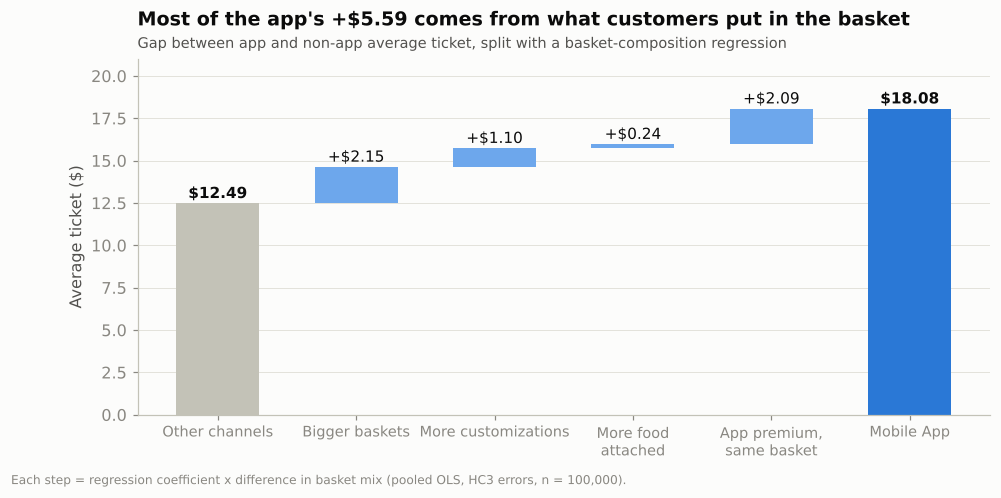

In [6]:
# Where does the app's ticket premium come from? Decompose the gap with a pooled basket model.
gap_model = smf.ols("revenue ~ items + customizations + food + app", data=d).fit(cov_type="HC3")
b = gap_model.params
diff = d.groupby("app")[["items", "customizations", "food", "revenue"]].mean()
delta = diff.loc[1] - diff.loc[0]
parts = pd.Series({
    "Bigger baskets": b["items"] * delta["items"],
    "More customizations": b["customizations"] * delta["customizations"],
    "More food attached": b["food"] * delta["food"],
    "App premium, same basket": b["app"],
})
parts["Unexplained"] = delta["revenue"] - parts.sum()
decomp = pd.DataFrame({"$ per order": parts, "share of gap": parts / delta["revenue"]})
display(decomp.round(3))
print(f"Non-app ticket ${diff.loc[0, 'revenue']:.2f} -> app ticket ${diff.loc[1, 'revenue']:.2f}, gap ${delta['revenue']:.2f}. "
      f"App vs non-app: +{delta['items']:.2f} items, +{delta['customizations']:.2f} customizations, "
      f"+{delta['food'] * 100:.1f} pts food attach")

fig, ax = plt.subplots(figsize=(10, 4.2))
steps = [("Other channels", diff.loc[0, "revenue"], "total")] + [(k, v, "step") for k, v in parts.items() if abs(v) > 0.005] \
        + [("Mobile App", diff.loc[1, "revenue"], "total")]
running = 0
for i, (label, v, kind) in enumerate(steps):
    if kind == "total":
        ax.bar(i, v, width=0.6, color=S.BLUE if label == "Mobile App" else S.NEUTRAL)
        ax.text(i, v + 0.3, f"${v:.2f}", ha="center", color=S.INK, fontsize=10, fontweight="bold")
        running = v
    else:
        ax.bar(i, v, bottom=running, width=0.6, color=S.SEQ_BLUES[2])
        ax.text(i, running + v + 0.3, f"+${v:.2f}", ha="center", color=S.INK, fontsize=10)
        running += v
ax.set_xticks(range(len(steps)), [s[0].replace(", ", ",\n").replace(" attached", "\nattached") for s in steps], fontsize=9.5)
ax.set_ylim(0, 21); ax.grid(axis="x", visible=False); ax.set_ylabel("Average ticket ($)")
ax.set_title("Most of the app's +$5.59 comes from what customers put in the basket")
S.subtitle(ax, "Gap between app and non-app average ticket, split with a basket-composition regression")
S.source(fig, "Each step = regression coefficient x difference in basket mix (pooled OLS, HC3 errors, n = 100,000).")
S.save(fig, "fig2_ticket_gap_decomposition")

Of the **$5.59** app gap:
- $2.15 comes from bigger baskets.
- $1.11 comes from customizations.
- $0.24 comes from food.

Together that is 62%, driven by **what** app customers buy. The remaining **$2.09** is a same-basket premium. The data has no item-level prices, so a likely cause, such as size upgrades or premium items that are easier to pick in the app, remains a hypothesis to check with item-level data.

In [7]:
# Price architecture: what a customer pays per item falls as baskets grow, because ~$1.74 is charged per order.
by_size = d.groupby("items").agg(orders=("revenue", "size"), avg_ticket=("revenue", "mean"))
by_size["revenue_per_item"] = by_size.avg_ticket / by_size.index
display(by_size.loc[[1, 2, 3, 4, 5, 6, 8, 10]].round(2).T)
cust_rev = ticket.params["customizations"] * d.customizations.sum()
print(f"Customizations: {d.customizations.mean():.2f} per order; {(d.customizations > 0).mean():.0%} of orders have at least one; "
      f"implied customization revenue = {cust_rev / d.revenue.sum():.1%} of all revenue")

items,1,2,3,4,5,6,8,10
orders,"6,849.000","18,079.000","23,982.000","21,615.000","14,572.000","8,226.000","1,696.000",287.000
avg_ticket,7.050,9.820,12.670,15.540,18.500,21.430,27.590,33.680
revenue_per_item,7.050,4.910,4.220,3.880,3.700,3.570,3.450,3.370


Customizations: 1.81 per order; 81% of orders have at least one; implied customization revenue = 11.3% of all revenue


Every order carries a ~$1.75 base charge regardless of size, so revenue per item falls from $7.05 on a one-item order to $3.37 on a ten-item order. Bundles and suggestive selling raise the ticket mainly through the $2.68 per-item term.

In [8]:
# What-if levers, sized on this sample. Price responses are ASSUMPTIONS (the data has no price variation).
N, R = len(d), d.revenue.sum()
bc, bi, bf = ticket.params["customizations"], ticket.params["items"], ticket.params["food"]
C_total = d.customizations.sum()
rows = []
for e in [0.0, -0.5, -1.0]:
    up = 0.10 / bc                                        # +$0.10 is a +10.8% customization price increase
    delta_rev = (bc + 0.10) * C_total * (1 + e * up) - bc * C_total
    rows.append(("Customization price +$0.10", f"customization volume elasticity {e:+.1f}", delta_rev))
rows.append(("Food attach rate +5 pts", "food premium only ($%.2f per order)" % bf, 0.05 * N * bf))
rows.append(("Food attach rate +5 pts", "food adds an item too ($%.2f per order)" % (bf + bi), 0.05 * N * (bf + bi)))
rows.append(("Basket size +0.1 items", "suggestive sell / bundles", 0.1 * N * bi))
levers = pd.DataFrame(rows, columns=["lever", "assumption", "revenue_change_$"])
levers["pct_of_revenue"] = levers["revenue_change_$"] / R
display(levers.style.format({"revenue_change_$": lambda v: f"{'-' if v < 0 else '+'}${abs(v):,.0f}", "pct_of_revenue": "{:+.2%}"}).hide(axis="index"))

lever,assumption,revenue_change_$,pct_of_revenue
Customization price +$0.10,customization volume elasticity +0.0,"+$18,108",+1.22%
Customization price +$0.10,customization volume elasticity -0.5,"+$8,074",+0.54%
Customization price +$0.10,customization volume elasticity -1.0,"-$1,959",-0.13%
Food attach rate +5 pts,food premium only ($1.61 per order),"+$8,036",+0.54%
Food attach rate +5 pts,food adds an item too ($4.29 per order),"+$21,456",+1.44%
Basket size +0.1 items,suggestive sell / bundles,"+$26,839",+1.81%


These levers are sized on the 100k-order sample. **The price responses are assumptions, not estimates.** A +$0.10 customization price is a 10.8% increase on the ~$0.93 average:
- If customization volume doesn't respond, it adds **+1.2%** of revenue.
- At elasticity −0.5, it adds +0.5%.
- At unit elasticity (−1.0), it changes revenue by −0.1%.

The downside is small and the upside is real, which is the profile of a lever worth **testing**. Raising basket size by 0.1 items (+1.8%) or food attach by 5 points (+0.5% to +1.4%) is comparable.

MDE_%,MDE_$,orders_per_arm_raw,orders_per_arm_adjusted
1.0%,$0.15,"21,538","16,128"
1.5%,$0.22,"9,573","7,168"
2.0%,$0.30,"5,385","4,032"
3.0%,$0.45,"2,394","1,792"
5.0%,$0.74,862,646


ticket sd $5.51; after adjusting for channel/age/region/store type $4.77 (25% variance removed); store ICC in this sample = 0.0001


PosixPath('/home/claude/qsr-revenue-growth/analysis/figures/fig3_price_test_power.png')

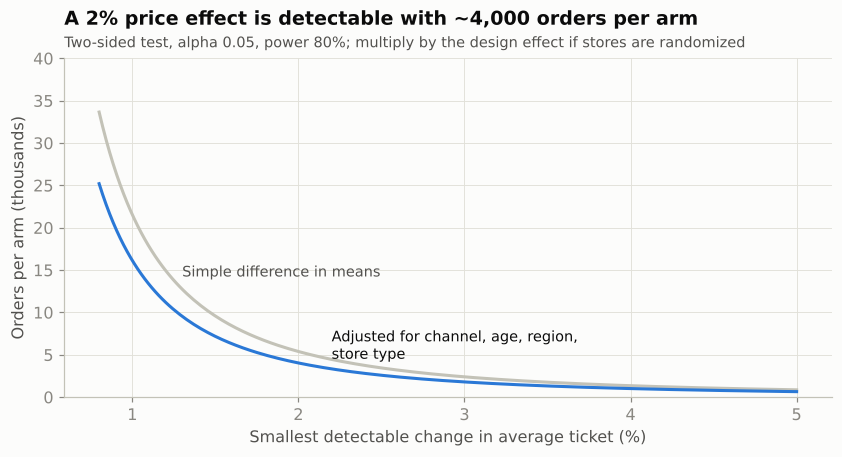

In [9]:
# Measuring price elasticity needs a test. How many orders per arm to detect a change in average ticket?
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
sd_raw = d.revenue.std()
pre = smf.ols("revenue ~ C(order_channel) + C(age_group) + C(region) + C(store_location_type)", data=d).fit()
sd_adj = np.sqrt(pre.mse_resid)            # regression adjustment on pre-treatment covariates (CUPED-style)
mean_ticket = d.revenue.mean()

# store-level clustering: intraclass correlation of ticket across stores (one-way ANOVA estimator)
g = d.groupby("store_id").revenue
k = g.size().mean()
msb = (g.size() * (g.mean() - mean_ticket) ** 2).sum() / (g.ngroups - 1)
msw = ((d.revenue - g.transform("mean")) ** 2).sum() / (len(d) - g.ngroups)
icc = max(0.0, (msb - msw) / (msb + (k - 1) * msw))

mdes = np.array([0.01, 0.015, 0.02, 0.03, 0.05])
power = pd.DataFrame({
    "MDE_%": mdes * 100, "MDE_$": mdes * mean_ticket,
    "orders_per_arm_raw": np.ceil(2 * z**2 * sd_raw**2 / (mdes * mean_ticket) ** 2),
    "orders_per_arm_adjusted": np.ceil(2 * z**2 * sd_adj**2 / (mdes * mean_ticket) ** 2),
})
display(power.style.format({"MDE_%": "{:.1f}%", "MDE_$": "${:.2f}", "orders_per_arm_raw": "{:,.0f}",
                            "orders_per_arm_adjusted": "{:,.0f}"}).hide(axis="index"))
print(f"ticket sd ${sd_raw:.2f}; after adjusting for channel/age/region/store type ${sd_adj:.2f} "
      f"({1 - sd_adj**2 / sd_raw**2:.0%} variance removed); store ICC in this sample = {icc:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
grid = np.linspace(0.008, 0.05, 200)
ax.plot(grid * 100, 2 * z**2 * sd_raw**2 / (grid * mean_ticket) ** 2 / 1000, color=S.NEUTRAL, lw=2)
ax.plot(grid * 100, 2 * z**2 * sd_adj**2 / (grid * mean_ticket) ** 2 / 1000, color=S.BLUE, lw=2)
ax.text(1.3, 2 * z**2 * sd_raw**2 / (0.013 * mean_ticket) ** 2 / 1000 + 1.5, "Simple difference in means", color=S.INK_2, fontsize=9.5)
ax.text(2.2, 2 * z**2 * sd_adj**2 / (0.022 * mean_ticket) ** 2 / 1000 + 1.2, "Adjusted for channel, age, region,\nstore type", color=S.INK, fontsize=9.5)
ax.set_xlabel("Smallest detectable change in average ticket (%)"); ax.set_ylabel("Orders per arm (thousands)")
ax.set_ylim(0, 40)
ax.set_title("A 2% price effect is detectable with ~4,000 orders per arm")
S.subtitle(ax, "Two-sided test, alpha 0.05, power 80%; multiply by the design effect if stores are randomized")
S.save(fig, "fig3_price_test_power")

**How to measure price response.** Use a randomized test.
- **Adjust for pre-treatment covariates.** Controlling for channel, age, region and store type removes 25% of ticket variance and cuts the required sample by a quarter. About 4,000 orders per arm then detect a 2% change.
- **Don't adjust for basket size or customizations.** A price change can move them, so they are not valid covariates.
- **Allow for store clustering.** Stores in this sample show none (ICC ≈ 0.0001), but real chains will. A store-randomized test needs the sample multiplied by the design effect 1 + (m − 1)·ICC, where m is the number of orders per store, and should be stratified by region and store type.

## 3. Demand: when customers order

In [10]:
hourly = q(f"select * from {T('qsr_marts', 'mart_hourly_demand')}")
by_hour = hourly.groupby("order_hour").orders.sum()
dayparts = hourly.groupby("daypart").agg(orders=("orders", "sum"), revenue=("revenue", "sum"))
dayparts["order_share"] = dayparts.orders / dayparts.orders.sum()
dayparts["avg_ticket"] = dayparts.revenue / dayparts.orders
display(dayparts.round(3))
mix = hourly.groupby(["daypart", "order_channel"]).orders.sum().unstack()
mix = mix.div(mix.sum(axis=1), axis=0)
print("App share of orders by daypart:", (mix["Mobile App"] * 100).round(1).to_dict())

daily = q(f"select order_date, sum(orders) as orders from {T('qsr_marts', 'mart_daily_kpis')} group by 1 order by 1")
daily["order_date"] = pd.to_datetime(daily.order_date)
daily = daily.set_index("order_date").orders.asfreq("D", fill_value=0)
dow_obs = daily.groupby(daily.index.dayofweek).sum()
dow_exp = daily.groupby(daily.index.dayofweek).size() / len(daily) * daily.sum()
month_obs = daily.groupby(daily.index.month).sum()
month_exp = daily.groupby(daily.index.month).size() / len(daily) * daily.sum()
print(f"daily orders: mean {daily.mean():.1f}, sd {daily.std():.1f}, variance/mean {daily.var() / daily.mean():.2f} (1.0 = pure Poisson noise)")
print(f"weekday effect: chi2 p = {stats.chisquare(dow_obs, dow_exp).pvalue:.2f};  month-of-year effect: chi2 p = {stats.chisquare(month_obs, month_exp).pvalue:.2f};  "
      f"2025 vs 2024 volume: {daily['2025'].sum() / daily['2024'].sum() - 1:+.1%}")

,orders,revenue,order_share,avg_ticket
daypart,,,,
1. Morning 5-10am,39442,"586,165.230",0.394,14.861
2. Midday 11am-1pm,21577,"321,231.820",0.216,14.888
3. Afternoon 2-5pm,24627,"365,565.920",0.246,14.844
4. Evening 6-9pm,10674,"158,967.580",0.107,14.893
5. Late night 10pm-4am,3680,"54,746.530",0.037,14.877


App share of orders by daypart: {'1. Morning 5-10am': 42.6, '2. Midday 11am-1pm': 42.6, '3. Afternoon 2-5pm': 42.2, '4. Evening 6-9pm': 42.8, '5. Late night 10pm-4am': 42.6}
daily orders: mean 137.0, sd 11.5, variance/mean 0.96 (1.0 = pure Poisson noise)
weekday effect: chi2 p = 0.63;  month-of-year effect: chi2 p = 0.73;  2025 vs 2024 volume: +0.3%


In [11]:
# One-day-ahead forecast backtest over the last 8 weeks.
test_days = daily.index[-56:]
f = pd.DataFrame(index=test_days)
f["actual"] = daily[test_days]
f["trailing_28d_mean"] = [daily[:t - pd.Timedelta(days=1)].iloc[-28:].mean() for t in test_days]
f["same_weekday_last_week"] = [daily[t - pd.Timedelta(days=7)] for t in test_days]
f["weekday_mean_8wk"] = [daily[[t - pd.Timedelta(days=7 * k) for k in range(1, 9)]].mean() for t in test_days]
err = pd.DataFrame({m: {"MAE": (f[m] - f.actual).abs().mean(), "MAPE_%": ((f[m] - f.actual).abs() / f.actual).mean() * 100}
                    for m in f.columns[1:]}).T
display(err.round(2))
lo, hi = stats.poisson.ppf([0.1, 0.9], daily.mean())
print(f"80% planning range for a day: {lo:.0f}-{hi:.0f} orders; morning (5-10am) = {dayparts.order_share.iloc[0]:.0%} of them")

peak = orders.assign(peak=orders.order_hour.isin([6, 7, 8, 12])).groupby(["order_channel", "peak"]).fulfillment_min.mean().unstack()
peak.columns = ["off-peak", "peak (6-9am, noon)"]
display(peak.loc[S.CHANNEL_ORDER].round(2))

,MAE,MAPE_%
trailing_28d_mean,9.790,7.350
same_weekday_last_week,13.680,10.200
weekday_mean_8wk,9.620,7.290


80% planning range for a day: 122-152 orders; morning (5-10am) = 39% of them


,off-peak,"peak (6-9am, noon)"
order_channel,,
Mobile App,4.510,4.510
Drive-Thru,5.800,5.820
In-Store Cashier,3.200,3.200
Kiosk,4.020,4.000


PosixPath('/home/claude/qsr-revenue-growth/analysis/figures/fig4_demand_by_hour_and_weekday.png')

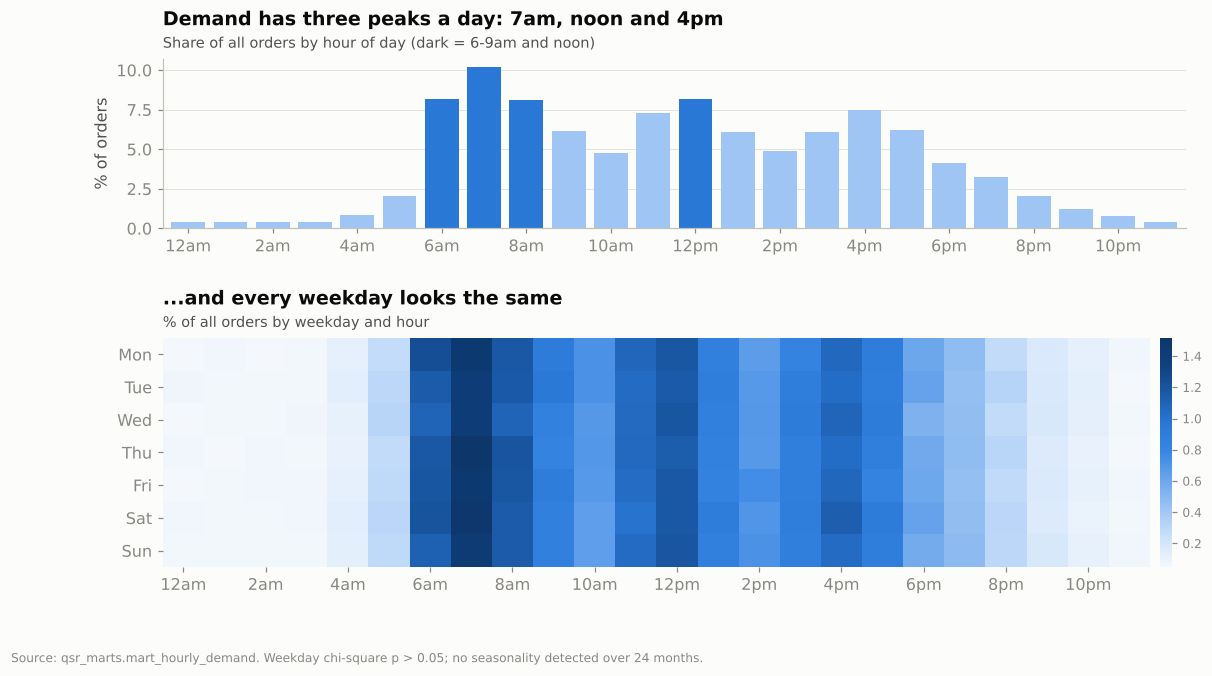

In [12]:
grid = hourly.groupby(["day_of_week_num", "order_hour"]).orders.sum().unstack().reindex(columns=range(24), fill_value=0)
share = grid / grid.values.sum() * 100
fig, axes = plt.subplots(2, 1, figsize=(12, 6), gridspec_kw={"height_ratios": [1, 1.35], "hspace": 0.55})
ax = axes[0]
colors = [S.BLUE if h in (6, 7, 8, 12) else S.SEQ_BLUES[1] for h in range(24)]
ax.bar(range(24), by_hour.reindex(range(24), fill_value=0) / by_hour.sum() * 100, color=colors, width=0.8)
ax.set_xticks(range(0, 24, 2), [f"{h % 12 or 12}{'am' if h < 12 else 'pm'}" for h in range(0, 24, 2)])
ax.set_xlim(-0.6, 23.6); ax.grid(axis="x", visible=False); ax.set_ylabel("% of orders")
ax.set_title("Demand has three peaks a day: 7am, noon and 4pm")
S.subtitle(ax, "Share of all orders by hour of day (dark = 6-9am and noon)")
ax = axes[1]
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blues", ["#f4f8fd"] + S.SEQ_BLUES)
im = ax.imshow(share.values, aspect="auto", cmap=cmap)
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 2), [f"{h % 12 or 12}{'am' if h < 12 else 'pm'}" for h in range(0, 24, 2)])
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("...and every weekday looks the same")
S.subtitle(ax, "% of all orders by weekday and hour")
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.outline.set_visible(False); cb.ax.tick_params(colors=S.MUTED, labelsize=8)
S.source(fig, "Source: qsr_marts.mart_hourly_demand. Weekday chi-square p > 0.05; no seasonality detected over 24 months.")
S.save(fig, "fig4_demand_by_hour_and_weekday")

**Volume follows the clock, not the calendar.** Mornings (5–10am) carry 39% of orders and the 7am hour alone carries 10%. Weekday and month-of-year differences are consistent with chance (χ² p = 0.63 and 0.73). Daily counts have variance/mean of 0.96, which is pure Poisson noise around 137 orders a day.

**Forecasting.**
- A weekday-aware forecast does no better than a 28-day average (MAPE 7.3% vs 7.4%).
- "Same day last week" does worse (10.2%) because it carries a single day's noise forward.
- For staffing, plan on 122–152 orders on 80% of days and staff to the daypart curve.

**Channel and fulfillment.** Channel mix is flat across dayparts (app 42–43% all day), and fulfillment time doesn't rise at peak hours. A real store would show queueing, so that is a limitation of the data.

## 4. Customers: age, loyalty and satisfaction

,Mobile App,Drive-Thru,In-Store Cashier,Kiosk,avg_ticket
age_group,,,,,
18-24,0.548,0.252,0.150,0.049,15.550
25-34,0.550,0.251,0.149,0.050,15.540
35-44,0.348,0.301,0.249,0.102,14.410
45-54,0.359,0.296,0.250,0.095,14.560
55+,0.098,0.346,0.458,0.098,13.060


,gap_vs_18-24_raw,gap_after_channel,p_after_channel
C(age_group)[T.25-34],-0.004,-0.013,0.765
C(age_group)[T.35-44],-1.133,-0.016,0.723
C(age_group)[T.45-54],-0.992,0.060,0.246
C(age_group)[T.55+],-2.492,0.019,0.737


PosixPath('/home/claude/qsr-revenue-growth/analysis/figures/fig5_app_adoption_by_age.png')

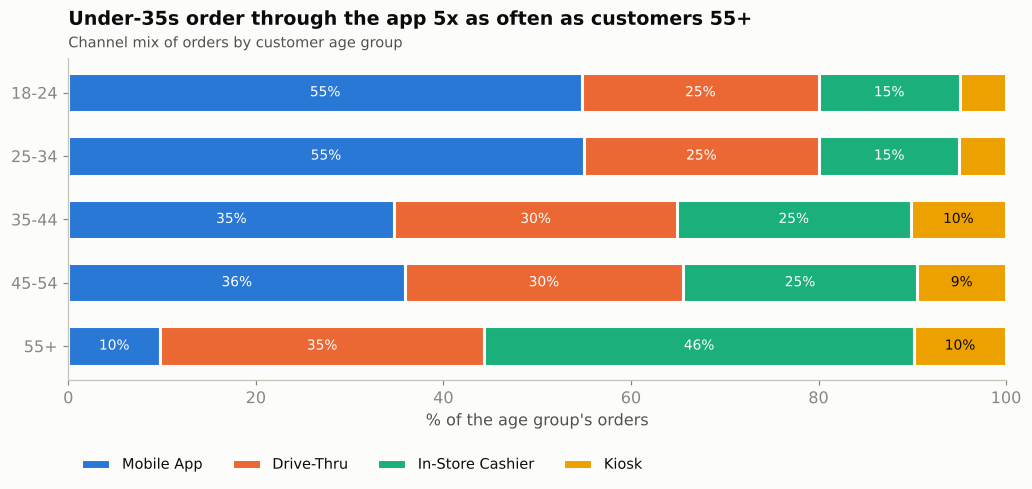

In [13]:
age_mix = pd.crosstab(orders.age_group, orders.order_channel, normalize="index")[S.CHANNEL_ORDER]
age_tix = orders.groupby("age_group").revenue.mean()
display(pd.concat([age_mix.round(3), age_tix.rename("avg_ticket").round(2)], axis=1))
raw = smf.ols("revenue ~ C(age_group)", data=d).fit(cov_type="HC3")
ctl = smf.ols(f"revenue ~ C(age_group) + {CH}", data=d).fit(cov_type="HC3")
age_terms = [k for k in raw.params.index if k.startswith("C(age")]
display(pd.DataFrame({"gap_vs_18-24_raw": raw.params[age_terms], "gap_after_channel": ctl.params[age_terms],
                      "p_after_channel": ctl.pvalues[age_terms]}).round(3))

fig, ax = plt.subplots(figsize=(11, 3.8))
groups = list(age_mix.index)[::-1]
left = np.zeros(len(groups))
for ch in S.CHANNEL_ORDER:
    v = age_mix.loc[groups, ch].values * 100
    ax.barh(groups, v, left=left, color=S.CHANNEL_COLORS[ch], height=0.62, edgecolor=S.SURFACE, linewidth=2, label=ch)
    for i, (l, w) in enumerate(zip(left, v)):
        if w >= 7:
            ax.text(l + w / 2, i, f"{w:.0f}%", ha="center", va="center", fontsize=9,
                    color=S.INK if ch == "Kiosk" else "white")
    left += v
ax.set_xlim(0, 100); ax.grid(False); ax.set_xlabel("% of the age group's orders")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.2), fontsize=9.5)
ax.set_title("Under-35s order through the app 5x as often as customers 55+")
S.subtitle(ax, "Channel mix of orders by customer age group")
S.save(fig, "fig5_app_adoption_by_age")

**Age changes the channel, not the spend.** The raw $2.50 ticket gap between 18–24 and 55+ disappears once channel is controlled (+$0.02, p = 0.78). Older customers spend less per order because fewer of them use the app.

,non_member,member,gap_$,gap_%
segment,,,,
All orders,14.090,15.720,1.630,11.570
Mobile App,18.070,18.080,0.010,0.050
Drive-Thru,12.490,12.470,-0.020,-0.170
In-Store Cashier,12.490,12.560,0.070,0.560
Kiosk,12.450,12.560,0.110,0.920


Rewards effect after controlling for channel: $+0.022 (95% CI -0.040 to +0.084); members place 58% of orders on the app vs 29% for non-members


PosixPath('/home/claude/qsr-revenue-growth/analysis/figures/fig6_rewards_gap_is_channel_mix.png')

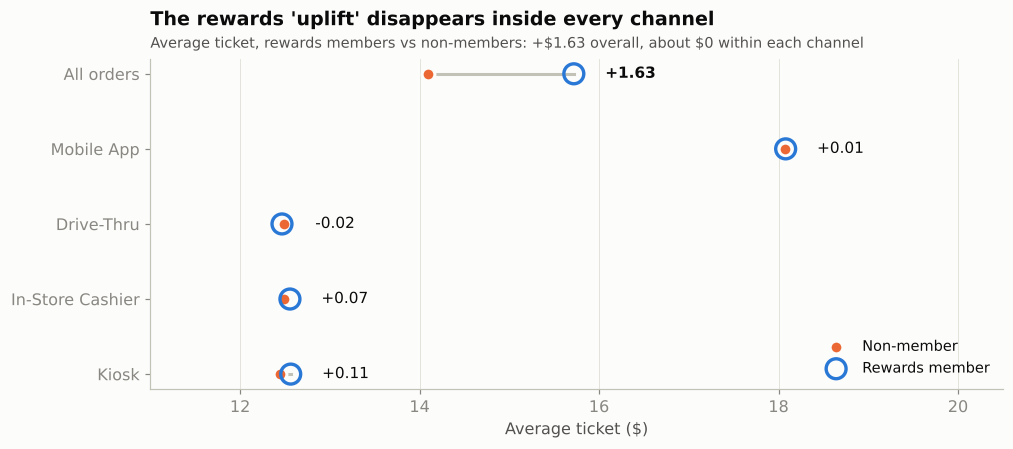

In [14]:
# Rewards members spend more... or do they? Compare overall and within each channel.
rows = [("All orders", orders)] + [(ch, orders[orders.order_channel == ch]) for ch in S.CHANNEL_ORDER]
rw = pd.DataFrame([{
    "segment": name,
    "non_member": g.loc[~g.is_rewards_member, "revenue"].mean(),
    "member": g.loc[g.is_rewards_member, "revenue"].mean(),
} for name, g in rows]).set_index("segment")
rw["gap_$"] = rw.member - rw.non_member
rw["gap_%"] = rw["gap_$"] / rw.non_member * 100
display(rw.round(2))
adj = smf.ols(f"revenue ~ rewards + {CH}", data=d).fit(cov_type="HC3")
print(f"Rewards effect after controlling for channel: ${adj.params['rewards']:+.3f} "
      f"(95% CI {adj.conf_int().loc['rewards', 0]:+.3f} to {adj.conf_int().loc['rewards', 1]:+.3f}); "
      f"members place {orders.loc[orders.is_rewards_member, 'is_app_order'].mean():.0%} of orders on the app vs "
      f"{orders.loc[~orders.is_rewards_member, 'is_app_order'].mean():.0%} for non-members")

fig, ax = plt.subplots(figsize=(10, 3.9))
segs = list(rw.index)[::-1]
for i, s in enumerate(segs):
    a, b2 = rw.loc[s, "non_member"], rw.loc[s, "member"]
    ax.plot([a, b2], [i, i], color=S.BASELINE, lw=2, zorder=1)
    ax.scatter([a], [i], s=70, color=S.ORANGE, zorder=2, edgecolor=S.SURFACE, linewidth=2, label="Non-member" if i == 0 else None)
    ax.scatter([b2], [i], s=170, facecolor="none", edgecolor=S.BLUE, linewidth=2.2, zorder=3, label="Rewards member" if i == 0 else None)
    ax.text(max(a, b2) + 0.35, i, f"{rw.loc[s, 'gap_$']:+.2f}", va="center", fontsize=10,
            color=S.INK, fontweight="bold" if s == "All orders" else "normal")
ax.set_yticks(range(len(segs)), segs); ax.set_xlim(11, 20.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("Average ticket ($)")
ax.legend(loc="lower right", fontsize=9.5)
ax.set_title("The rewards 'uplift' disappears inside every channel")
S.subtitle(ax, "Average ticket, rewards members vs non-members: +$1.63 overall, about $0 within each channel")
S.save(fig, "fig6_rewards_gap_is_channel_mix")

**This is the classic loyalty-measurement trap.** Comparing members with non-members credits the program with an 11.6% higher ticket. Within each channel, though, the gap is −$0.02 to +$0.11, and the channel-adjusted effect is +$0.02 with a confidence interval that includes zero.

Members are simply twice as likely to order on the app (58% vs 29% of orders), and the app has the higher ticket. A loyalty ROI case built on the raw comparison would overstate the program by about $1.63 per order.

Satisfaction per extra minute of fulfillment: pooled -0.037, within channel +0.0007 (95% CI -0.005 to +0.007)


,channel_effect_vs_drive_thru,p
"C(order_channel, Treatment('Drive-Thru'))[T.In-Store Cashier]",0.259,0.000
"C(order_channel, Treatment('Drive-Thru'))[T.Kiosk]",0.156,0.000
"C(order_channel, Treatment('Drive-Thru'))[T.Mobile App]",0.415,0.000


PosixPath('/home/claude/qsr-revenue-growth/analysis/figures/fig7_satisfaction_vs_fulfillment.png')

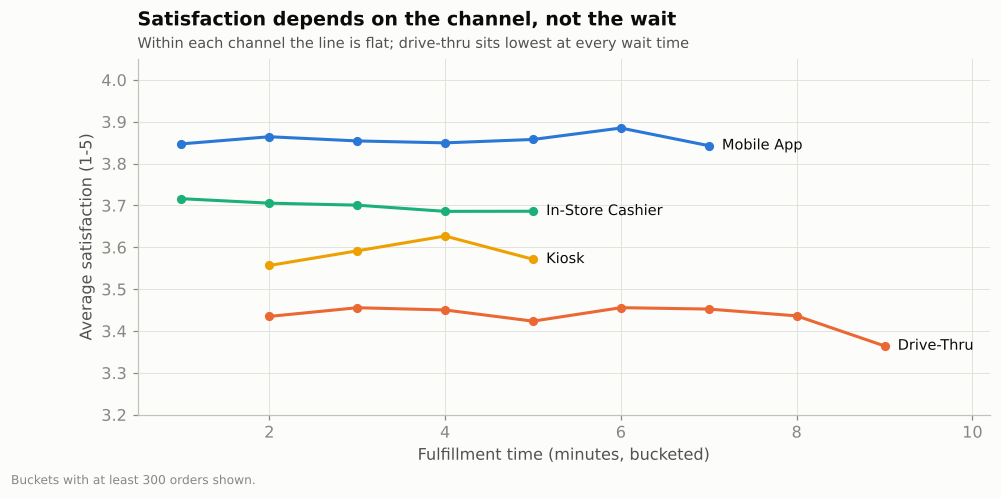

In [15]:
pooled = smf.ols("satisfaction_score ~ fulfillment_min", data=d).fit(cov_type="HC3")
within = smf.ols(f"satisfaction_score ~ fulfillment_min + {CH}", data=d).fit(cov_type="HC3")
print(f"Satisfaction per extra minute of fulfillment: pooled {pooled.params['fulfillment_min']:+.3f}, "
      f"within channel {within.params['fulfillment_min']:+.4f} (95% CI {within.conf_int().loc['fulfillment_min', 0]:+.3f} "
      f"to {within.conf_int().loc['fulfillment_min', 1]:+.3f})")
display(pd.DataFrame({"channel_effect_vs_drive_thru": within.params.filter(like="T."),
                      "p": within.pvalues.filter(like="T.")}).round(3))

curve = d.groupby(["order_channel", "fulfillment_bucket_min"]).satisfaction_score.agg(["mean", "size"]).reset_index()
curve = curve[curve["size"] >= 300]
fig, ax = plt.subplots(figsize=(10, 4.2))
for ch in S.CHANNEL_ORDER:
    c = curve[curve.order_channel == ch]
    ax.plot(c.fulfillment_bucket_min, c["mean"], color=S.CHANNEL_COLORS[ch], marker="o", ms=5, lw=2)
    ax.text(c.fulfillment_bucket_min.iloc[-1] + 0.15, c["mean"].iloc[-1], ch, va="center", fontsize=9.5, color=S.INK)
ax.set_xlim(0.5, 10.2); ax.set_ylim(3.2, 4.05)
ax.set_xlabel("Fulfillment time (minutes, bucketed)"); ax.set_ylabel("Average satisfaction (1-5)")
ax.set_title("Satisfaction depends on the channel, not the wait")
S.subtitle(ax, "Within each channel the line is flat; drive-thru sits lowest at every wait time")
S.source(fig, "Buckets with at least 300 orders shown.")
S.save(fig, "fig7_satisfaction_vs_fulfillment")

**Pooled, each extra minute of wait appears to cost 0.037 satisfaction points. Within a channel it costs nothing** (+0.001, CI −0.005 to +0.007). The pooled slope exists only because drive-thru is both the slowest channel (5.8 min) and the least liked.

So shaving minutes off the drive-thru would not close its 0.42-point gap to the app. The next questions are about order accuracy, menu-board experience and payment friction.

In [16]:
# Opportunity sizing: move part of the 35-54 group's non-app orders onto the app.
mid = orders.age_group.isin(["35-44", "45-54"])
mid_non_app = (mid & ~orders.is_app_order).sum()
gap = delta["revenue"]
opp = pd.DataFrame([{"orders_shifted": int(round(s * mid_non_app)), "basket_capture": cap,
                     "revenue_change_$": s * mid_non_app * gap * cap}
                    for s in (0.05, 0.10) for cap in (0.25, 0.50, 1.00)])
opp["pct_of_revenue"] = opp["revenue_change_$"] / R
display(opp.style.format({"orders_shifted": "{:,}", "basket_capture": "{:.0%}", "revenue_change_$": "${:,.0f}",
                          "pct_of_revenue": "{:+.2%}"}).hide(axis="index"))
print(f"35-54 customers: {mid.mean():.0%} of orders, {orders.loc[mid, 'is_app_order'].mean():.0%} on the app; "
      f"{mid_non_app:,} non-app orders in the sample")

orders_shifted,basket_capture,revenue_change_$,pct_of_revenue
"1,293",25%,"$1,805",+0.12%
"1,293",50%,"$3,610",+0.24%
"1,293",100%,"$7,219",+0.49%
"2,586",25%,"$3,610",+0.24%
"2,586",50%,"$7,219",+0.49%
"2,586",100%,"$14,439",+0.97%


35-54 customers: 40% of orders, 35% on the app; 25,860 non-app orders in the sample


**Sizing app migration.** Moving 10% of the 35–54 group's non-app orders (about 2,600 orders) onto the app is worth **+0.24% to +0.97%** of revenue. The range depends on how much of the app basket those customers adopt.

Even the high end is below 1%, because most app value already comes from customers who use it. This sizing assumes migrated customers behave like current app users, which is exactly what a pilot should test. One example is an app-download offer at the drive-thru for 35–54 rewards members, measured against a holdout.

## 5. Strategy context: 30 years of Starbucks 10-K filings

In [17]:
tl = q(f"select * from {T('qsr_marts', 'mart_strategy_timeline')}").sort_values("fiscal_year").set_index("fiscal_year")
cols = ["ceo", "total_stores", "net_new_stores", "store_growth_pct", "pct_international", "pct_licensed",
        "us_stores_per_million", "is_breakdown_complete", "mobile_per_10k", "digital_per_10k", "rewards_per_10k"]
display(tl.loc[[1996, 2000, 2008, 2009, 2012, 2016, 2019, 2020, 2023, 2024, 2025], cols])
prior = tl.loc[tl.index < 2025]
slow = prior[prior.store_growth_pct < tl.loc[2025, "store_growth_pct"]]
print(f"FY2025 net new stores: {tl.loc[2025, 'net_new_stores']:.0f} ({tl.loc[2025, 'store_growth_pct']:.1f}%); "
      f"slower years since 1996: {list(slow.index)}")
print("US population check (millions):", (tl.us_population.loc[[2019, 2020, 2021, 2022, 2023, 2024, 2025]] / 1e6).round(1).to_dict())

comp = q(f"select * from {T('qsr_marts', 'mart_competitor_language')}")
terms = ["franchise", "licensed", "drive", "digital", "mobile", "app", "loyalty", "delivery"]
cmp25 = comp[comp.fiscal_year == 2025].pivot(index="keyword", columns="company", values="per_10k_words").loc[terms]
display(cmp25.round(1))

,ceo,total_stores,net_new_stores,store_growth_pct,pct_international,pct_licensed,us_stores_per_million,is_breakdown_complete,mobile_per_10k,digital_per_10k,rewards_per_10k
fiscal_year,,,,,,,,,,,
1996,Howard Schultz (1st),1006,<NA>,NaN,0.000,7.500,3.700,False,0.000,0.000,0.000
2000,Orin Smith,3501,1003,40.150,15.000,25.200,10.500,True,0.000,0.000,0.000
2008,Howard Schultz (2nd),16680,1924,13.040,30.700,44.700,38.000,True,0.000,0.000,0.000
2009,Howard Schultz (2nd),16635,-45,-0.270,33.100,46.900,36.300,True,0.000,0.000,0.000
2012,Howard Schultz (2nd),17066,63,0.370,33.000,47.200,36.500,True,0.000,2.916,2.916
2016,Howard Schultz (2nd),25085,2042,8.860,42.900,46.000,40.800,False,11.390,0.000,8.542
2019,Kevin Johnson,31256,1391,4.660,46.800,47.000,45.800,False,10.689,2.672,5.345
2020,Kevin Johnson,32660,1404,4.490,53.100,49.100,46.200,True,18.454,6.920,9.227
2023,Laxman Narasimhan,38038,2327,6.520,57.000,48.500,49.100,True,17.061,12.796,8.531


FY2025 net new stores: 377 (0.9%); slower years since 1996: [2009, 2011, 2012]
US population check (millions): {2019: 328.2, 2020: 331.5, 2021: 331.9, 2022: 332.4, 2023: 332.8, 2024: 333.3, 2025: 333.8}


company,McDonald's,Starbucks
keyword,,
franchise,91.400,0.000
licensed,9.100,45.300
drive,11.400,3.500
digital,6.900,8.700
mobile,0.000,8.700
app,16.000,24.400
loyalty,13.700,7.000
delivery,2.300,5.200


**Footprint.** Starbucks grew from 1,006 stores (FY1996) to **40,576** (FY2025).
- International stores are now 58% of the total.
- About half of all stores are licensed.
- FY2025 added only **377** net stores (+0.9%), the slowest growth since FY2012.

**Two data-quality notes:**
1. The ownership × geography breakdowns don't sum to the reported totals in FY2013–FY2019 (partial table parsing, gaps of 2,000–3,000 stores) or in FY1996–98 (estimated licensed counts, 2–28 stores). Shares use the parsed components, and a dbt test flags those years.
2. The state population file runs ~2% below the Census Bureau's Vintage 2024 estimate for July 2024 (333.3M vs 340.1M). Recent US stores-per-million (~50.8) is therefore slightly overstated.

PosixPath('/home/claude/qsr-revenue-growth/analysis/figures/fig10_starbucks_vs_mcdonalds_language.png')

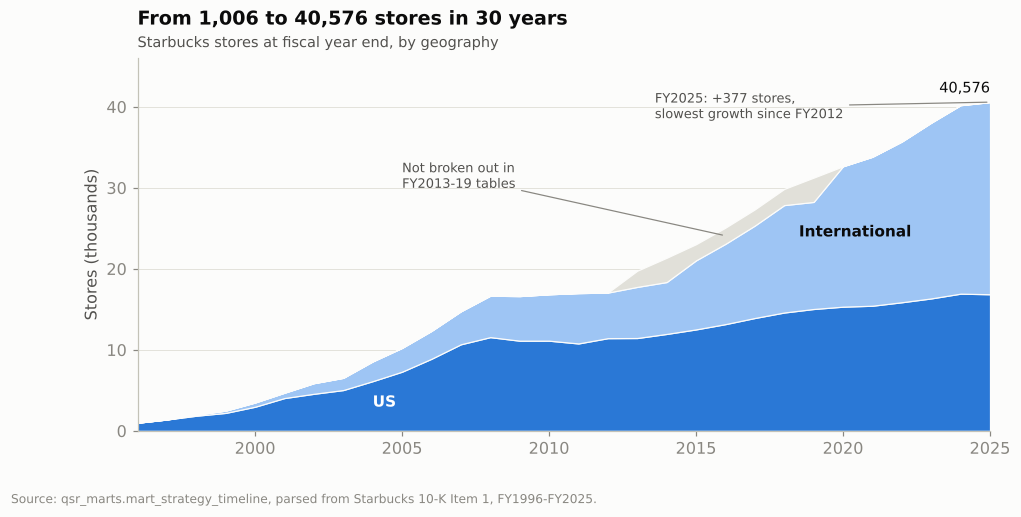

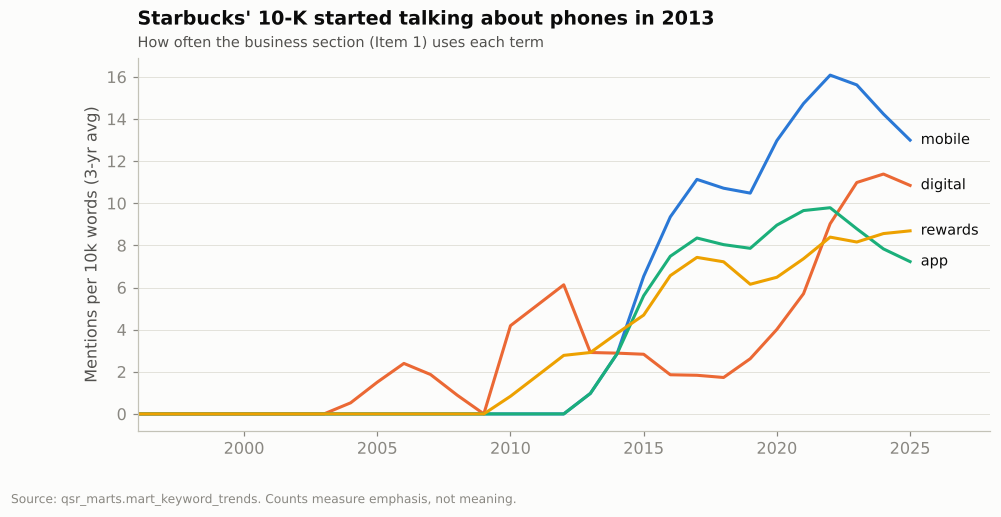

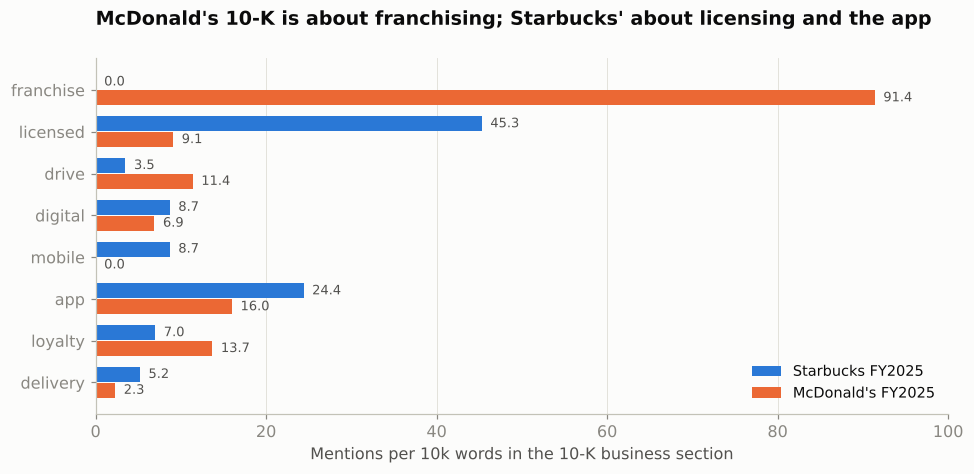

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.4))
yrs = tl.index.values
us, intl = tl.us_stores.values / 1000, tl.international_stores.values / 1000
unalloc = (tl.total_stores - tl.us_stores - tl.international_stores).clip(lower=0).values / 1000
ax.stackplot(yrs, us, intl, unalloc, colors=[S.BLUE, S.SEQ_BLUES[1], "#e1e0d9"], edgecolor=S.SURFACE, linewidth=0.8)
ax.text(2004, 3.0, "US", color="white", fontsize=10, fontweight="bold")
ax.text(2018.5, 24, "International", color=S.INK, fontsize=10, fontweight="bold")
ax.annotate("Not broken out in\nFY2013-19 tables", xy=(2016, (tl.loc[2016, "total_stores"] - 1000) / 1000), xytext=(2005, 30),
            fontsize=8.5, color=S.INK_2, arrowprops=dict(arrowstyle="-", color=S.MUTED, lw=0.8))
ax.text(2025, tl.loc[2025, "total_stores"] / 1000 + 1.2, f"{tl.loc[2025, 'total_stores']:,.0f}", ha="right", fontsize=9.5)
ax.annotate(f"FY2025: +{tl.loc[2025, 'net_new_stores']:.0f} stores,\nslowest growth since FY2012", xy=(2025, tl.loc[2025, "total_stores"] / 1000),
            xytext=(2013.6, 38.6), fontsize=8.5, color=S.INK_2, arrowprops=dict(arrowstyle="-", color=S.MUTED, lw=0.8))
ax.set_xlim(1996, 2025); ax.set_ylim(0, 46); ax.set_ylabel("Stores (thousands)"); ax.grid(axis="x", visible=False)
ax.set_title("From 1,006 to 40,576 stores in 30 years")
S.subtitle(ax, "Starbucks stores at fiscal year end, by geography")
S.source(fig, "Source: qsr_marts.mart_strategy_timeline, parsed from Starbucks 10-K Item 1, FY1996-FY2025.")
S.save(fig, "fig8_store_footprint")

fig, ax = plt.subplots(figsize=(10, 4.4))
kw = q(f"select * from {T('qsr_marts', 'mart_keyword_trends')}")
for term, color in [("mobile", S.BLUE), ("digital", S.ORANGE), ("app", S.AQUA), ("rewards", S.YELLOW)]:
    s3 = kw[kw.keyword == term].sort_values("fiscal_year").set_index("fiscal_year").per_10k_words.rolling(3, min_periods=1).mean()
    ax.plot(s3.index, s3.values, color=color, lw=2)
    ax.text(2025.4, s3.iloc[-1], term, color=S.INK, fontsize=9.5, va="center")
ax.set_xlim(1996, 2028); ax.set_ylabel("Mentions per 10k words (3-yr avg)"); ax.grid(axis="x", visible=False)
ax.set_title("Starbucks' 10-K started talking about phones in 2013")
S.subtitle(ax, "How often the business section (Item 1) uses each term")
S.source(fig, "Source: qsr_marts.mart_keyword_trends. Counts measure emphasis, not meaning.")
S.save(fig, "fig9_10k_language_trends")

fig, ax = plt.subplots(figsize=(10, 4.2))
yy = np.arange(len(terms))[::-1]
ax.barh(yy + 0.19, cmp25.loc[terms, "Starbucks"], height=0.36, color=S.BLUE, label="Starbucks FY2025")
ax.barh(yy - 0.19, cmp25.loc[terms, "McDonald's"], height=0.36, color=S.ORANGE, label="McDonald's FY2025")
for i, t in zip(yy, terms):
    for off, co in [(0.19, "Starbucks"), (-0.19, "McDonald's")]:
        v = cmp25.loc[t, co]
        ax.text(v + 1, i + off, f"{v:.1f}", va="center", fontsize=8.5, color=S.INK_2)
ax.set_yticks(yy, terms); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("Mentions per 10k words in the 10-K business section")
ax.legend(loc="lower right", fontsize=9.5)
ax.set_title("McDonald's 10-K is about franchising; Starbucks' about licensing and the app")
S.save(fig, "fig10_starbucks_vs_mcdonalds_language")

**The language shift matches the order data.**
- "Mobile" first appears in Starbucks' FY2013 10-K and peaks in FY2020–23, alongside "digital", "app" and "rewards".
- McDonald's describes itself through **franchising** (91 mentions per 10k words; Starbucks has none) and "drive".
- Starbucks describes itself through **licensing** and the **app**.

Both put digital and loyalty at the center, and section 1 shows why: the app is where the bigger tickets are.

## 6. Recommendations for a revenue growth team

1. **Grow app share among 35–54 customers before chasing price.** They are the largest movable pool: 40% of orders, only 35% on the app. Pilot an app-adoption offer against a holdout and measure ticket and frequency.
2. **Test customization pricing.** Customizations are 11% of revenue and appear on 81% of orders, and the modeled downside at unit elasticity is about −0.1%. Use a store-randomized test stratified by region and store type, sized at ~4,000 orders per arm for a 2% effect before the store design effect.
3. **Report loyalty impact within channel.** The raw member/non-member gap overstates the program by ~$1.63 per order. Use channel-adjusted or matched comparisons.
4. **Diagnose the drive-thru experience, not just its speed.** Satisfaction gaps are channel-level. Collect order-accuracy and friction data before investing only in speed.
5. **Staff to the daypart curve.** Weekday-specific forecasts add nothing here; a 28-day rolling mean with a Poisson band is enough.

**Limitations.**
- The order data appears simulated: no item prices, no price changes, no persistent customer behavior, no store effects and no queueing.
- Every causal reading above is observational and stated as a hypothesis to test.
- The pipeline, data tests, models and test-design method carry over unchanged to real POS data.